# Pollution EDA, Time-Series Diagnostics, and Festival Analysis

**Prepared by:** Yashvi Patel

This notebook analyzes the cleaned daily pollution file and reconstructs the hourly PM2.5 and NO2 series from the project raw exports. It covers limit-level days, monthly and hourly patterns, AQI categories, distribution diagnostics, time-series diagnostics, and selected 2025 Indian festivals. The exported daily CSV is read but never overwritten.

Run this notebook in Jupyter with pandas, numpy, matplotlib, scipy, statsmodels, and requests installed. The 24-hour PM2.5 reference line is 60 ug/m^3. The hourly parser uses the local timestamp string's first 19 characters, matching the cleaning notebook. Some statistics can differ from planning figures if the processed CSV or its calculation definition differs; results below are calculated from the files loaded here.

In [1]:
from pathlib import Path
from io import StringIO
from datetime import datetime
import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

# Find the repository when Jupyter starts in the repository, its parent, or notebooks.
required_input = Path("data/processed/pollution_daily.csv")
root_candidates = [Path.cwd(), *Path.cwd().parents]
root_candidates += [candidate / "EDA-Group-Project" for candidate in root_candidates]
PROJECT_ROOT = next(
    (candidate for candidate in root_candidates if (candidate / required_input).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find {required_input} from {Path.cwd()}. "
        "Start Jupyter in the project or notebooks directory."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "air_quality"
DAILY_PATH = PROJECT_ROOT / required_input
DAILY_STANDARD = 60.0
STUDY_START = pd.Timestamp("2025-03-01")
STUDY_END = pd.Timestamp("2025-11-30")
STUDY_HOURLY_END = pd.Timestamp("2025-11-30 23:00:00")
FULL_HOURLY_INDEX = pd.date_range(
    "2025-03-01 05:00:00", "2025-12-01 04:00:00", freq="h", name="time"
)

required_daily_columns = {"date", "pm25", "no2", "pm25_hours", "pm_no2_ratio"}
daily = pd.read_csv(DAILY_PATH, parse_dates=["date"])
missing_daily_columns = required_daily_columns.difference(daily.columns)
if missing_daily_columns:
    raise ValueError(f"Daily CSV is missing columns: {sorted(missing_daily_columns)}")
daily = daily.sort_values("date").reset_index(drop=True)
if daily["date"].duplicated().any():
    raise ValueError("The daily CSV contains duplicate dates.")
if daily["date"].min() != STUDY_START or daily["date"].max() != STUDY_END:
    raise ValueError("The daily CSV does not cover the expected March-November 2025 period.")


def load_hourly_series(filename, series_name):
    """Read local timestamps and restore the complete hourly calendar."""
    raw = pd.read_csv(RAW_DIR / filename)
    required_columns = {"datetime_from_local", "value"}
    missing_columns = required_columns.difference(raw.columns)
    if missing_columns:
        raise ValueError(f"{filename} is missing columns: {sorted(missing_columns)}")

    raw["time"] = pd.to_datetime(raw["datetime_from_local"].str[:19], errors="raise")
    raw["value"] = pd.to_numeric(raw["value"], errors="raise")
    if raw["time"].duplicated().any():
        raise ValueError(f"Duplicate local timestamps found in {filename}.")
    series = raw.set_index("time")["value"].sort_index().asfreq("h")
    series = series.reindex(FULL_HOURLY_INDEX)
    series.name = series_name
    return raw, series


pm_raw, pm_hourly = load_hourly_series("pm25_hourly_mar_nov.csv", "PM2.5")
no2_raw, no2_hourly = load_hourly_series("no2_hourly_mar_nov.csv", "NO2")

# Exact-zero NO2 values were treated as likely sensor-floor readings in P3.
no2_zero_count = int(no2_hourly.eq(0).sum())
no2_hourly = no2_hourly.mask(no2_hourly.eq(0))
study_pm = pm_hourly.loc[:STUDY_HOURLY_END].copy()
study_no2 = no2_hourly.loc[:STUDY_HOURLY_END].copy()
daily_valid = daily.dropna(subset=["pm25"]).copy()

print("Project directory:", PROJECT_ROOT)
print("Daily rows / valid PM2.5 days:", len(daily), "/", len(daily_valid))
print("Hourly calendar rows:", len(pm_hourly), "(expected 6,600)")
print("Raw hourly PM2.5 / NO2 rows:", len(pm_raw), "/", len(no2_raw))
print("Exact-zero NO2 readings masked for analysis:", no2_zero_count)
if len(pm_hourly) != 6600 or len(no2_hourly) != 6600:
    raise ValueError("The reconstructed hourly calendar is not 6,600 hours.")

Project directory: c:\Users\YASHVI PATEL\Documents\Study Only\EDA\EDA-PROJECT\EDA-Group-Project
Daily rows / valid PM2.5 days: 275 / 271
Hourly calendar rows: 6600 (expected 6,600)
Raw hourly PM2.5 / NO2 rows: 5914 / 5985
Exact-zero NO2 readings masked for analysis: 3


## 1. Daily PM2.5 and limit-level days

The daily means are compared with India's 24-hour PM2.5 standard of 60 ug/m^3. A breach is counted strictly as a daily mean **greater than** 60 ug/m^3; missing days are excluded.

Days above 60 ug/m^3: 88 of 271 valid days
The project brief cites 89 breach days, but a strict >60 rule on this CSV gives 88. Check the data version or threshold convention before reporting.


,valid_days,breach_days,breach_percent
month,,,
March,31,7,22.6
April,29,18,62.1
May,30,14,46.7
June,28,5,17.9
July,31,0,0.0
August,31,0,0.0
September,30,1,3.3
October,31,13,41.9
November,30,30,100.0


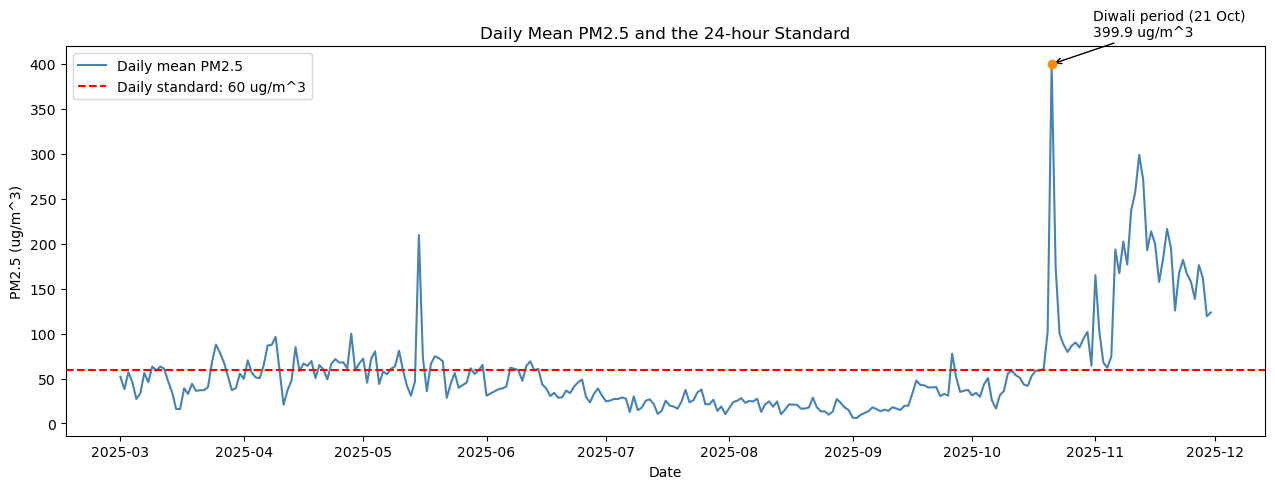

In [2]:
daily_valid = daily.dropna(subset=["pm25"]).copy()
above_standard = daily_valid["pm25"].gt(DAILY_STANDARD)
breach_days = int(above_standard.sum())
valid_days = int(len(daily_valid))
print(f"Days above {DAILY_STANDARD:.0f} ug/m^3: {breach_days} of {valid_days} valid days")
if valid_days != 271:
    print(f"The project brief expects 271 valid days; this CSV contains {valid_days}.")
if breach_days != 89:
    print(
        "The project brief cites 89 breach days, but a strict >60 rule on this CSV "
        f"gives {breach_days}. Check the data version or threshold convention before reporting."
    )

monthly_breaches = daily_valid.assign(month=daily_valid["date"].dt.month).groupby("month").agg(
    valid_days=("pm25", "size"),
    breach_days=("pm25", lambda values: int(values.gt(DAILY_STANDARD).sum())),
)
monthly_breaches["breach_percent"] = (
    100 * monthly_breaches["breach_days"] / monthly_breaches["valid_days"]
)
monthly_breaches.index = pd.Index(
    [calendar.month_name[month] for month in monthly_breaches.index], name="month"
)
display(monthly_breaches.round({"breach_percent": 1}))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily_valid["date"], daily_valid["pm25"], color="steelblue", linewidth=1.5, label="Daily mean PM2.5")
ax.axhline(DAILY_STANDARD, color="red", linestyle="--", linewidth=1.5, label="Daily standard: 60 ug/m^3")
diwali = daily_valid.loc[daily_valid["date"].eq(pd.Timestamp("2025-10-21"))]
if len(diwali) != 1:
    raise ValueError("Expected one valid daily PM2.5 value for 2025-10-21.")
diwali_date = diwali["date"].iloc[0]
diwali_value = float(diwali["pm25"].iloc[0])
ax.scatter([diwali_date], [diwali_value], color="darkorange", zorder=4)
ax.annotate(
    f"Diwali period (21 Oct)\n{diwali_value:.1f} ug/m^3",
    xy=(diwali_date, diwali_value),
    xytext=(30, 20),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "black"},
)
ax.set_title("Daily Mean PM2.5 and the 24-hour Standard")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m^3)")
ax.legend()
fig.tight_layout()
plt.show()

The breach table shows a clear seasonal shift: exceedances are frequent in spring, drop to very few during the monsoon months, and rise again in October and November. November has the most breach days in this file. The daily series marks the elevated October 21 Diwali-period mean; timing alone does not prove that the festival caused the peak.

## 2. Monthly distributions and hourly diurnal profiles

The box and violin plots use valid daily means. The hourly profiles use available cleaned hourly observations from March 1 through November 30; the missing hours remain missing.

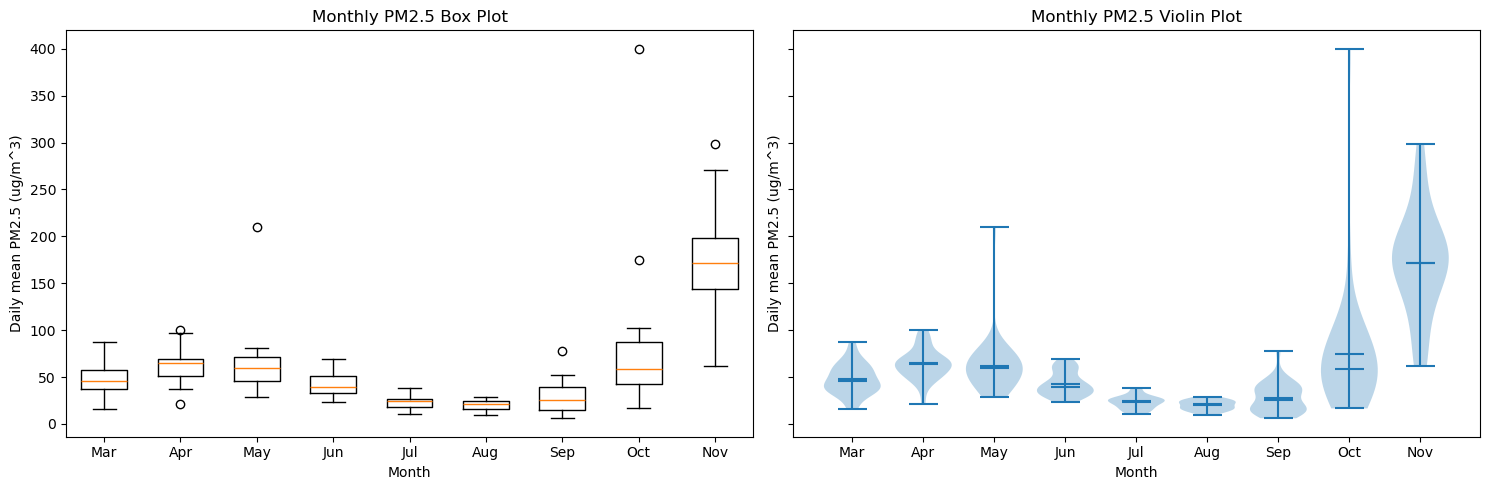

In [3]:
month_numbers = list(range(3, 12))
month_labels = [calendar.month_abbr[month] for month in month_numbers]
monthly_values = [
    daily_valid.loc[daily_valid["date"].dt.month.eq(month), "pm25"].to_numpy()
    for month in month_numbers
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
axes[0].boxplot(monthly_values, positions=month_numbers, widths=0.6, showfliers=True)
axes[0].set_title("Monthly PM2.5 Box Plot")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Daily mean PM2.5 (ug/m^3)")
axes[0].set_xticks(month_numbers, month_labels)

axes[1].violinplot(
    monthly_values, positions=month_numbers, widths=0.8,
    showmeans=True, showmedians=True, showextrema=True,
)
axes[1].set_title("Monthly PM2.5 Violin Plot")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Daily mean PM2.5 (ug/m^3)")
axes[1].set_xticks(month_numbers, month_labels)
fig.tight_layout()
plt.show()

The monthly plots show both the typical daily level and the spread of high-pollution days. The distributions are lower through much of the monsoon period and shift upward again in autumn, while a few extreme days stretch the upper tails.

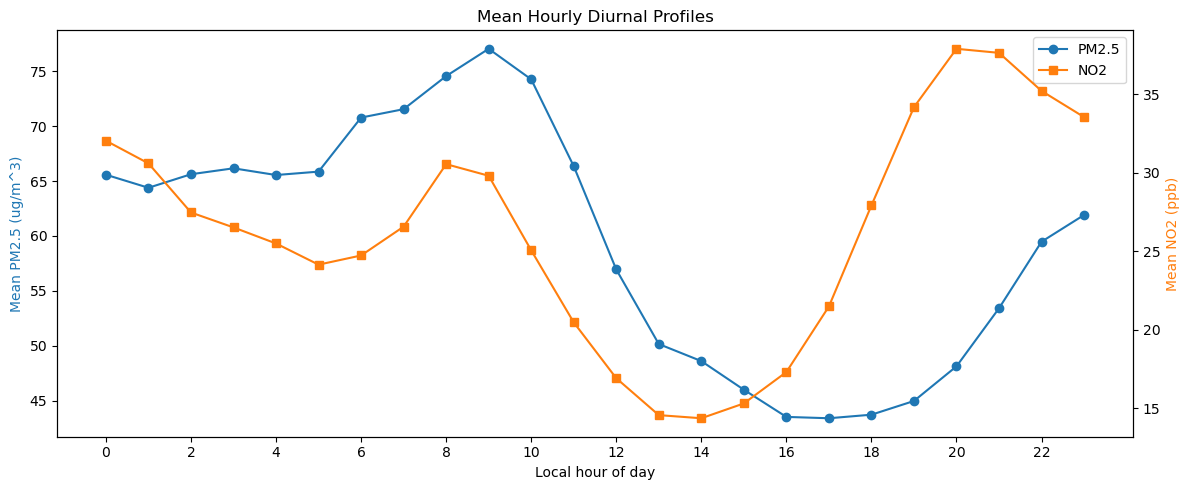

PM2.5 hourly-profile minimum: 17 :00


In [4]:
pm_by_hour = study_pm.groupby(study_pm.index.hour).mean().reindex(range(24))
no2_by_hour = study_no2.groupby(study_no2.index.hour).mean().reindex(range(24))
hours = np.arange(24)

fig, ax_pm = plt.subplots(figsize=(12, 5))
ax_no2 = ax_pm.twinx()
line_pm = ax_pm.plot(hours, pm_by_hour, color="tab:blue", marker="o", label="PM2.5")
line_no2 = ax_no2.plot(hours, no2_by_hour, color="tab:orange", marker="s", label="NO2")
ax_pm.set_title("Mean Hourly Diurnal Profiles")
ax_pm.set_xlabel("Local hour of day")
ax_pm.set_ylabel("Mean PM2.5 (ug/m^3)", color="tab:blue")
ax_no2.set_ylabel("Mean NO2 (ppb)", color="tab:orange")
ax_pm.set_xticks(range(0, 24, 2))
ax_pm.legend(line_pm + line_no2, [line.get_label() for line in line_pm + line_no2], loc="upper right")
fig.tight_layout()
plt.show()
print("PM2.5 hourly-profile minimum:", int(pm_by_hour.idxmin()), ":00")

In this dataset, mean PM2.5 is lowest near 5 PM. Daytime solar heating can strengthen vertical mixing in the atmospheric boundary layer and dilute near-surface pollution; this is a plausible explanation, not a causal result established by the profile alone.

## 3. Indian AQI categories and the PM2.5/NO2 ratio

For the daily PM2.5 categories, the integer bands are applied as continuous intervals: 0 to 30, >30 to 60, >60 to 90, >90 to 120, >120 to <250, and >=250 ug/m^3. This avoids overlapping endpoints for decimal measurements.

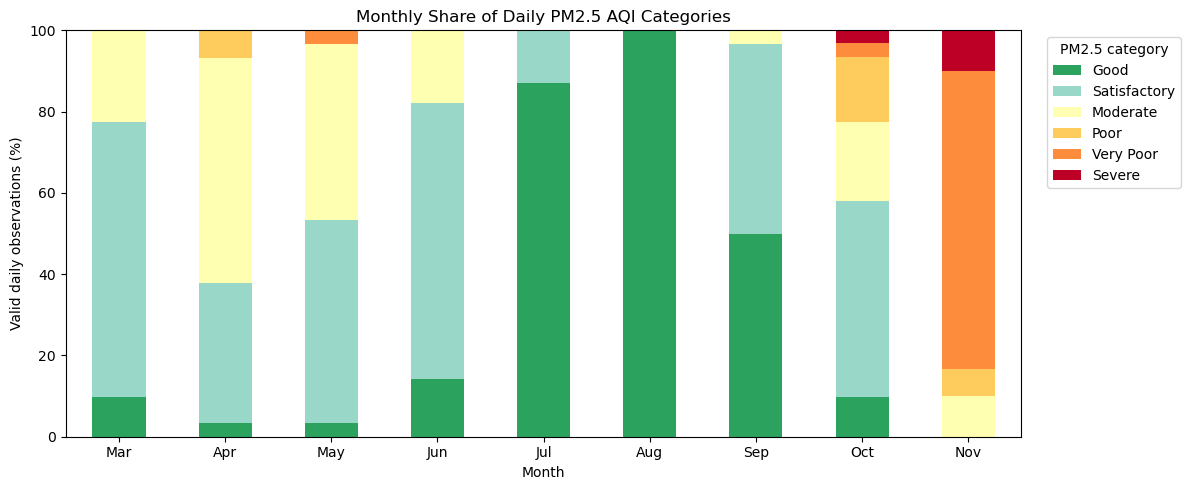

In [5]:
aqi_labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
pm_values = daily["pm25"]
aqi_conditions = [
    pm_values.ge(0) & pm_values.le(30),
    pm_values.gt(30) & pm_values.le(60),
    pm_values.gt(60) & pm_values.le(90),
    pm_values.gt(90) & pm_values.le(120),
    pm_values.gt(120) & pm_values.lt(250),
    pm_values.ge(250),
]
daily["aqi_category"] = pd.Categorical(
    np.select(aqi_conditions, aqi_labels, default=None),
    categories=aqi_labels,
    ordered=True,
)
category_share = pd.crosstab(
    daily["date"].dt.month, daily["aqi_category"], normalize="index"
).reindex(index=month_numbers, columns=aqi_labels, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
category_share.plot(
    kind="bar", stacked=True, ax=ax,
    color=["#2ca25f", "#99d8c9", "#ffffb2", "#fecc5c", "#fd8d3c", "#bd0026"],
)
ax.set_title("Monthly Share of Daily PM2.5 AQI Categories")
ax.set_xlabel("Month")
ax.set_ylabel("Valid daily observations (%)")
ax.set_xticklabels(month_labels, rotation=0)
ax.set_ylim(0, 100)
ax.legend(title="PM2.5 category", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

The stacked bars compare the share of valid days in each PM2.5 band, rather than comparing raw counts from months with different numbers of valid days. Missing daily values are excluded from the category breakdown. Values at exactly 250 ug/m^3 are assigned to Severe, following the "250+" definition in the brief.

,CSV mean daily ratio,Brief reference
month,,
March,1.3,1.3
April,1.6,NaN
May,1.9,NaN
June,4.0,4.1
July,1.1,1.1
August,1.1,NaN
September,2.3,NaN
October,4.2,3.9
November,5.6,5.6


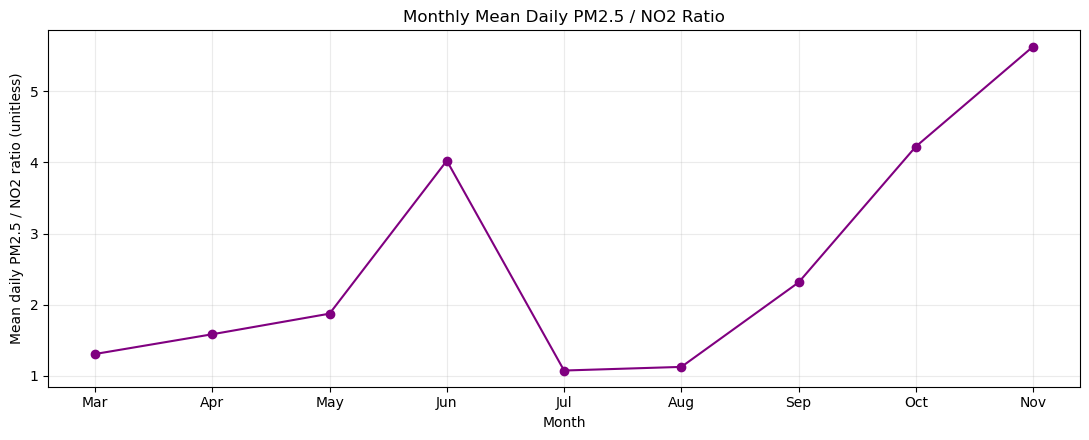

In [6]:
ratio_data = daily.dropna(subset=["pm_no2_ratio"]).copy()
ratio_data["month"] = ratio_data["date"].dt.month
monthly_mean_ratio = ratio_data.groupby("month")["pm_no2_ratio"].mean().reindex(month_numbers)

# Reference values from the project brief are shown beside, not substituted for, CSV results.
brief_reference = pd.Series(
    {3: 1.3, 6: 4.1, 7: 1.1, 10: 3.9, 11: 5.6}, name="Brief reference"
)
ratio_comparison = pd.concat(
    [monthly_mean_ratio.rename("CSV mean daily ratio"), brief_reference], axis=1
)
ratio_comparison.index = pd.Index(
    [calendar.month_name[month] for month in ratio_comparison.index], name="month"
)
display(ratio_comparison.round(1))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(month_numbers, monthly_mean_ratio, marker="o", color="purple")
ax.set_title("Monthly Mean Daily PM2.5 / NO2 Ratio")
ax.set_xlabel("Month")
ax.set_ylabel("Mean daily PM2.5 / NO2 ratio (unitless)")
ax.set_xticks(month_numbers, month_labels)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

The CSV's mean daily ratio is about 4.0 in June and 4.2 in October, compared with 4.1 and 3.9 in the brief; March, July, and November are close to the listed values. A higher PM2.5-to-NO2 ratio can be consistent with additional non-traffic particle sources such as smoke, but the ratio by itself cannot identify an emissions source.

## 4. Statistical tests and distribution fitting

The weekday/weekend test uses observed hourly NO2 from the study period. Exact-zero NO2 values are excluded, following the P3 sensor-floor handling.

In [7]:
no2_observed = study_no2.dropna()
weekday_mask = no2_observed.index.dayofweek < 5
weekday_no2 = no2_observed.loc[weekday_mask]
weekend_no2 = no2_observed.loc[~weekday_mask]
weekday_weekend_test = stats.mannwhitneyu(
    weekday_no2, weekend_no2, alternative="two-sided", method="asymptotic"
)
print("Weekday observations:", len(weekday_no2))
print("Weekend observations:", len(weekend_no2))
print(f"Mann-Whitney U statistic: {weekday_weekend_test.statistic:.1f}")
print(f"Weekday vs weekend NO2 p-value: {weekday_weekend_test.pvalue:.6f}")

Weekday observations: 4222
Weekend observations: 1755
Mann-Whitney U statistic: 3703243.5
Weekday vs weekend NO2 p-value: 0.979502


The Mann-Whitney p-value is about 0.980 for this CSV and hourly filter, rather than the brief's approximate 0.996; it is still above 0.05, so we do not reject the null hypothesis.
This is not proof that weekday and weekend NO2 are identical; it only means this test finds no clear difference in this sample.

Shapiro-Wilk raw PM2.5 (n=5000): W=0.6695, p=1.881e-71
Shapiro-Wilk log(1 + PM2.5) (n=5000): W=0.9954, p=1.545e-11


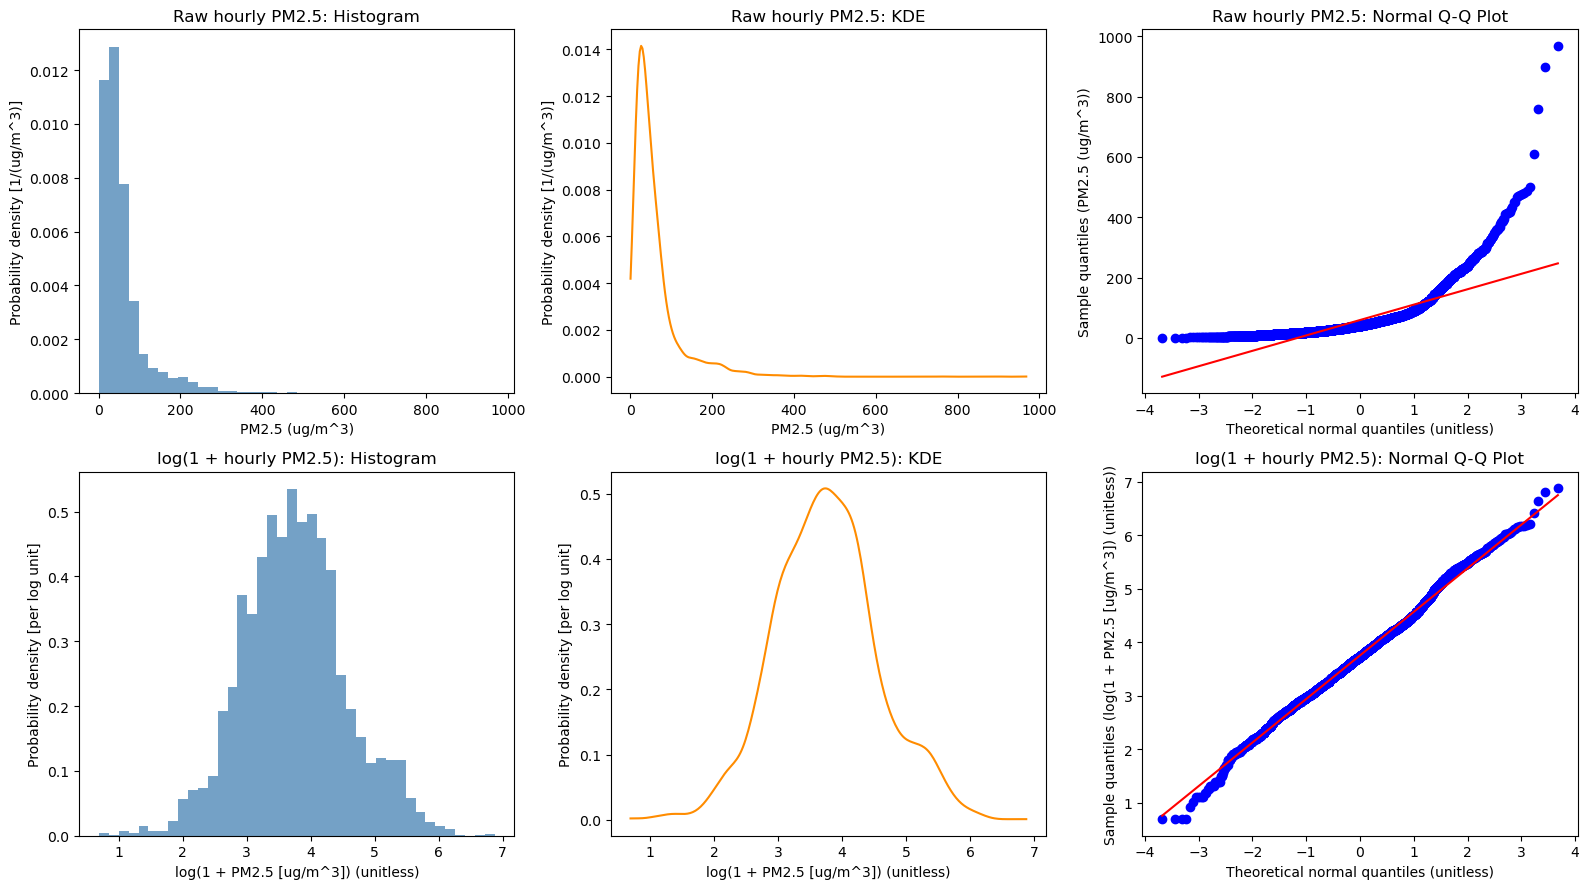

In [8]:
raw_pm = study_pm.dropna().to_numpy(dtype=float)
if len(raw_pm) < 3:
    raise ValueError("At least three observed hourly PM2.5 values are required for these diagnostics.")
if np.any(raw_pm < 0):
    raise ValueError("PM2.5 values must be non-negative for log(1 + PM2.5) diagnostics.")
log_pm = np.log1p(raw_pm)

# Shapiro-Wilk is evaluated on a deterministic sample of at most 5,000 values.
rng = np.random.default_rng(2025)
shapiro_size = min(5000, len(raw_pm))
shapiro_indices = rng.choice(len(raw_pm), size=shapiro_size, replace=False)
raw_sample = raw_pm[shapiro_indices]
log_sample = log_pm[shapiro_indices]
raw_shapiro = stats.shapiro(raw_sample)
log_shapiro = stats.shapiro(log_sample)
print(f"Shapiro-Wilk raw PM2.5 (n={shapiro_size}): W={raw_shapiro.statistic:.4f}, p={raw_shapiro.pvalue:.4g}")
print(f"Shapiro-Wilk log(1 + PM2.5) (n={shapiro_size}): W={log_shapiro.statistic:.4f}, p={log_shapiro.pvalue:.4g}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, values, short_name, x_label in [
    (0, raw_pm, "Raw hourly PM2.5", "PM2.5 (ug/m^3)"),
    (1, log_pm, "log(1 + hourly PM2.5)", "log(1 + PM2.5 [ug/m^3]) (unitless)"),
]:
    axes[row, 0].hist(values, bins=40, density=True, color="steelblue", alpha=0.75)
    axes[row, 0].set_title(f"{short_name}: Histogram")
    axes[row, 0].set_xlabel(x_label)
    density_unit = "1/(ug/m^3)" if row == 0 else "per log unit"
    axes[row, 0].set_ylabel(f"Probability density [{density_unit}]")

    grid = np.linspace(float(values.min()), float(values.max()), 300)
    kde = stats.gaussian_kde(values)
    axes[row, 1].plot(grid, kde(grid), color="darkorange")
    axes[row, 1].set_title(f"{short_name}: KDE")
    axes[row, 1].set_xlabel(x_label)
    axes[row, 1].set_ylabel(f"Probability density [{density_unit}]")

    stats.probplot(values, dist="norm", plot=axes[row, 2])
    axes[row, 2].set_title(f"{short_name}: Normal Q-Q Plot")
    axes[row, 2].set_xlabel("Theoretical normal quantiles (unitless)")
    axes[row, 2].set_ylabel(f"Sample quantiles ({x_label})")
fig.tight_layout()
plt.show()

The log transform makes the PM2.5 distribution much closer to a normal shape, but both Shapiro-Wilk p-values remain below 0.05 in this large sample.
The Q-Q plots show where the data depart from a normal distribution, especially in the upper tail.

,AIC,KS distance
distribution,,
Log-normal,58706.739,0.031
Gamma,59482.851,0.079


Lower AIC indicates the better relative fit among these two fitted candidates.


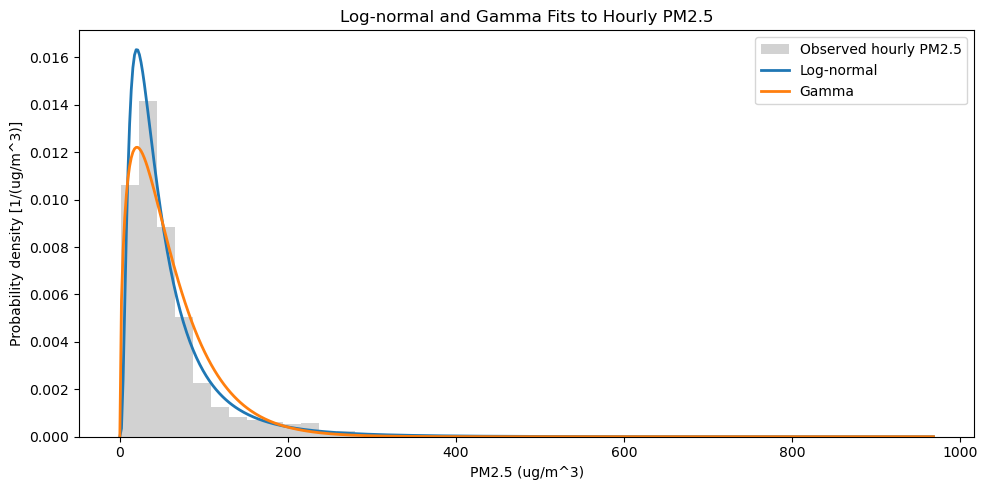

In [9]:
fit_values = raw_pm[raw_pm > 0]
if len(fit_values) != len(raw_pm):
    print(f"Distribution fits use positive hourly values only: {len(fit_values)} of {len(raw_pm)} observations.")
if len(fit_values) < 3:
    raise ValueError("At least three positive PM2.5 values are required for distribution fitting.")

fit_specs = [("Log-normal", stats.lognorm), ("Gamma", stats.gamma)]
fit_parameters = {}
fit_rows = []
for label, distribution in fit_specs:
    parameters = distribution.fit(fit_values, floc=0)
    fit_parameters[label] = parameters
    log_likelihood = float(np.sum(distribution.logpdf(fit_values, *parameters)))
    parameter_count = len(parameters) - 1  # loc is fixed at zero
    aic = 2 * parameter_count - 2 * log_likelihood
    ks_distance = stats.kstest(fit_values, distribution.cdf, args=parameters).statistic
    fit_rows.append({"distribution": label, "AIC": aic, "KS distance": ks_distance})
fit_results = pd.DataFrame(fit_rows).set_index("distribution").sort_values("AIC")
display(fit_results.round(3))
print("Lower AIC indicates the better relative fit among these two fitted candidates.")

x_fit = np.linspace(0, float(fit_values.max()), 500)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(fit_values, bins=45, density=True, alpha=0.35, color="gray", label="Observed hourly PM2.5")
for label, distribution in fit_specs:
    parameters = fit_parameters[label]
    ax.plot(x_fit, distribution.pdf(x_fit, *parameters), linewidth=2, label=label)
ax.set_title("Log-normal and Gamma Fits to Hourly PM2.5")
ax.set_xlabel("PM2.5 (ug/m^3)")
ax.set_ylabel("Probability density [1/(ug/m^3)]")
ax.legend()
fig.tight_layout()
plt.show()

For this CSV, the log-normal fit has the lower AIC and KS distance than the Gamma fit, so it fits these two candidates better.
Neither distribution is a proven model of pollution concentrations; this comparison is only descriptive.

## 5. Time-series diagnostics (P4b)

Four dates have no daily PM2.5 value in the exported dataset. A regular daily series is needed for ADF, ACF/PACF, and STL, so an analysis-only copy below fills only these short internal missing runs by time interpolation. The original `daily` values and exported CSV are not changed.

Missing daily means filled in the diagnostics-only series: 4
ADF statistic: -2.0779
ADF p-value: 0.253506
ADF lags used: 4; observations: 270
ADF critical values: {'1%': np.float64(-3.4548), '5%': np.float64(-2.8723), '10%': np.float64(-2.5725)}


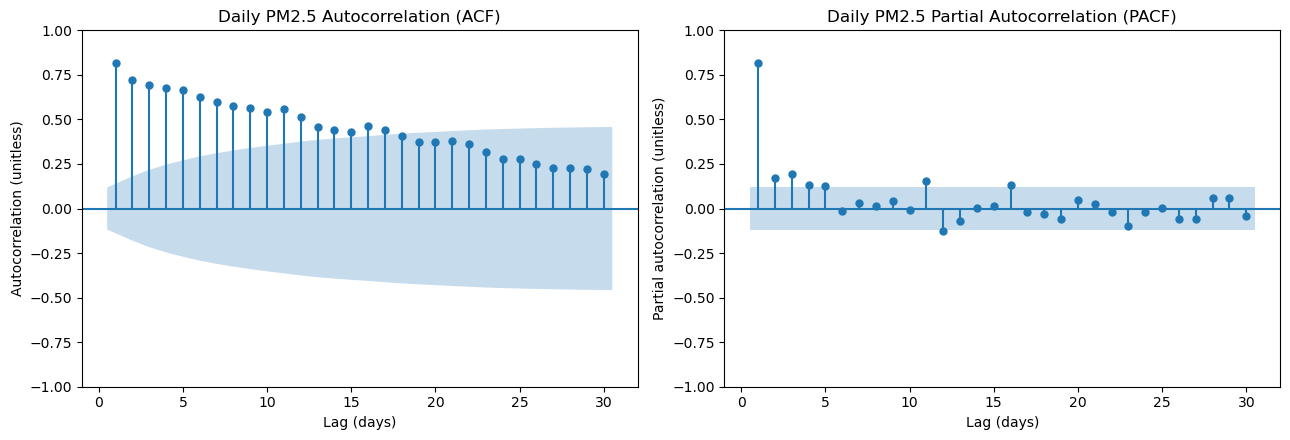

In [10]:
daily_pm = daily.set_index("date")["pm25"].astype(float).sort_index()
diagnostic_pm = daily_pm.interpolate(method="time", limit=3, limit_area="inside")
filled_days = int((daily_pm.isna() & diagnostic_pm.notna()).sum())
if diagnostic_pm.isna().any():
    raise ValueError("Time-series diagnostics require a complete daily series after the limited interpolation.")
print("Missing daily means filled in the diagnostics-only series:", filled_days)

adf_result = adfuller(diagnostic_pm, regression="c", autolag="AIC")
print(f"ADF statistic: {adf_result[0]:.4f}")
print(f"ADF p-value: {adf_result[1]:.6f}")
print(f"ADF lags used: {adf_result[2]}; observations: {adf_result[3]}")
print("ADF critical values:", {key: round(value, 4) for key, value in adf_result[4].items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_acf(diagnostic_pm, lags=30, ax=axes[0], zero=False)
axes[0].set_title("Daily PM2.5 Autocorrelation (ACF)")
axes[0].set_xlabel("Lag (days)")
axes[0].set_ylabel("Autocorrelation (unitless)")
plot_pacf(diagnostic_pm, lags=30, method="ywm", ax=axes[1], zero=False)
axes[1].set_title("Daily PM2.5 Partial Autocorrelation (PACF)")
axes[1].set_xlabel("Lag (days)")
axes[1].set_ylabel("Partial autocorrelation (unitless)")
fig.tight_layout()
plt.show()

The ADF p-value is about 0.262, above 0.05, so this test does not reject the unit-root null for the daily series.
The result uses four interpolated outage days in a diagnostics-only copy and should be treated as an exploratory check.

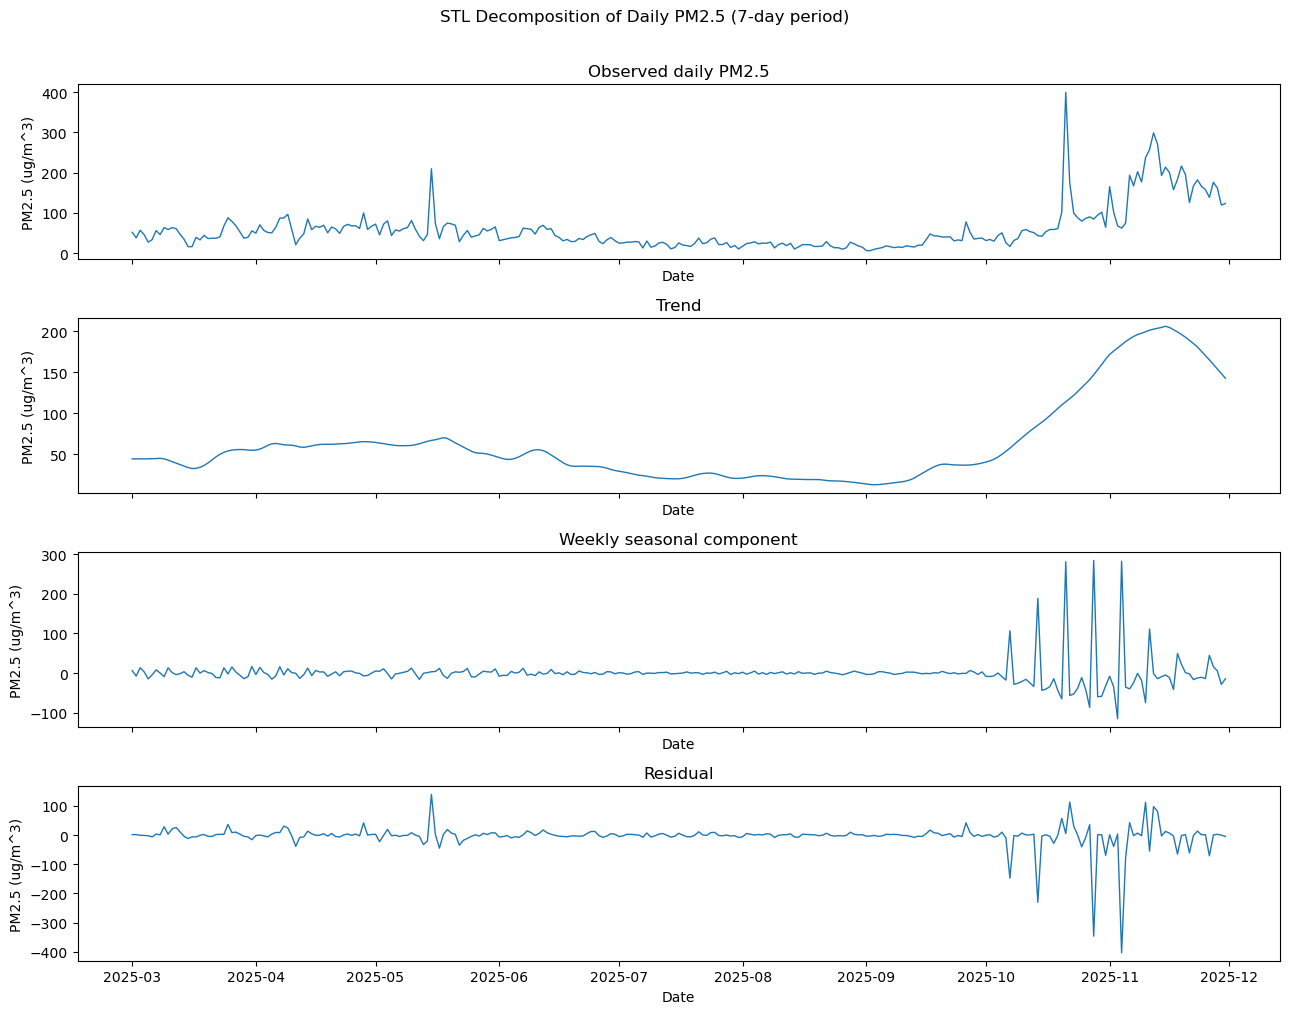

In [11]:
stl_result = STL(diagnostic_pm, period=7, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
components = [
    (diagnostic_pm, "Observed daily PM2.5"),
    (stl_result.trend, "Trend"),
    (stl_result.seasonal, "Weekly seasonal component"),
    (stl_result.resid, "Residual"),
]
for ax, (component, title) in zip(axes, components):
    ax.plot(component.index, component, color="tab:blue", linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("PM2.5 (ug/m^3)")
    ax.set_xlabel("Date")
fig.suptitle("STL Decomposition of Daily PM2.5 (7-day period)", y=1.01)
fig.tight_layout()
plt.show()

The STL decomposition separates a smooth trend, a repeating 7-day component, and the remaining residual variation. The seasonal component is a weekly pattern in this dataset and should not be read as a causal or annual seasonal effect.

## 6. Festival dates and hypothesis test (P4c)

The code tries to read India's 2025 public-holiday table from [Office Holidays](https://www.officeholidays.com/countries/india/2025) with `requests` and `pandas.read_html`. If the page is blocked or cannot be parsed, a short, documented set of major 2025 festival and national-observance dates is used instead. The flag is added only to this notebook's in-memory `daily` DataFrame.

In [12]:
FESTIVAL_URL = "https://www.officeholidays.com/countries/india/2025"
FALLBACK_FESTIVAL_DATES = pd.to_datetime([
    "2025-03-13",  # Holika Dahan
    "2025-03-14",  # Holi
    "2025-03-15",  # Regional Holi observance
    "2025-03-31",  # Eid al-Fitr
    "2025-04-06",  # Ram Navami
    "2025-04-10",  # Mahavir Jayanti
    "2025-04-14",  # Bohag Bihu
    "2025-04-16",  # Bohag Bihu observance
    "2025-04-18",  # Good Friday
    "2025-05-12",  # Buddha Purnima
    "2025-06-08",  # Eid al-Adha (listed date on the source page)
    "2025-07-06",  # Muharram
    "2025-08-15",  # Independence Day
    "2025-08-16",  # Janmashtami
    "2025-08-27",  # Ganesh Chaturthi
    "2025-08-28",  # Regional Ganesh Chaturthi observance
    "2025-09-12",  # Eid e-Milad observance
    "2025-10-01",  # Dussehra
    "2025-10-02",  # Gandhi Jayanti / Dussehra
    "2025-10-03",  # Vijaya Dashami observance
    "2025-10-04",  # Regional Vijaya Dashami observance
    "2025-10-20",  # Diwali
    "2025-10-21",  # Diwali / Govardhan Puja
    "2025-10-22",  # Govardhan Puja
    "2025-10-23",  # Bhai Dooj
    "2025-10-27",  # Chhath Puja
    "2025-10-28",  # Chhath Puja observance
    "2025-11-05",  # Guru Nanak Jayanti
]).normalize()
FESTIVAL_KEYWORDS = [
    r"\bholi\b", "holika dahan", "eid", "ram navami", "mahavir jayanti", "good friday",
    "buddha purnima", "muharram", "janmashtami", "ganesh", "independence day", "bohag bihu",
    "gandhi jayanti", "dussehra", "vijayadashami", "diwali", "deepavali",
    "govardhan", "bhai dooj", "chhath", "guru nanak",
]

festival_dates = pd.DatetimeIndex([], dtype="datetime64[ns]")
festival_date_source = "Office Holidays website"
try:
    response = requests.get(
        FESTIVAL_URL,
        headers={"User-Agent": "Mozilla/5.0 (compatible; EDA-course-project/1.0)"},
        timeout=15,
    )
    response.raise_for_status()
    holiday_tables = pd.read_html(StringIO(response.text))
    scraped_dates = []
    keyword_pattern = "|".join(FESTIVAL_KEYWORDS)
    for table in holiday_tables:
        columns = {str(column).strip().lower(): column for column in table.columns}
        date_column = next((column for name, column in columns.items() if "date" in name), None)
        name_column = next(
            (column for name, column in columns.items() if "holiday" in name or name == "name"),
            None,
        )
        if date_column is None or name_column is None:
            continue
        names = table[name_column].astype(str)
        selected = table.loc[names.str.contains(keyword_pattern, case=False, regex=True)].copy()
        if selected.empty:
            continue
        date_text = selected[date_column].astype(str).str.strip()

        def parse_festival_date(value):
            text = str(value).strip()
            if "2025" not in text:
                text = f"{text} 2025"
            formats = (
                "%b %d %Y", "%B %d %Y", "%b %d, %Y", "%B %d, %Y",
                "%a %b %d %Y", "%A %B %d %Y", "%a, %b %d %Y", "%A, %B %d %Y",
            )
            for date_format in formats:
                try:
                    return pd.Timestamp(datetime.strptime(text, date_format))
                except ValueError:
                    continue
            return pd.NaT

        parsed_dates = date_text.map(parse_festival_date)
        if parsed_dates.isna().any():
            print("Unparsed holiday date cells skipped:", int(parsed_dates.isna().sum()))
        scraped_dates.extend(parsed_dates.dropna().dt.normalize().tolist())
    festival_dates = pd.DatetimeIndex(scraped_dates).drop_duplicates().sort_values()
    festival_dates = festival_dates[
        (festival_dates >= STUDY_START) & (festival_dates <= STUDY_END)
    ]
    if len(festival_dates) < 3:
        raise ValueError("The holiday page did not yield enough selected dates for this study period.")
except (requests.RequestException, ValueError, ImportError) as error:
    print(f"Festival-date scraping unavailable ({type(error).__name__}: {error}). Using the 2025 fallback list.")
    festival_dates = FALLBACK_FESTIVAL_DATES[
        (FALLBACK_FESTIVAL_DATES >= STUDY_START) & (FALLBACK_FESTIVAL_DATES <= STUDY_END)
    ]
    festival_date_source = "curated 2025 fallback list"

print("Festival-date source:", festival_date_source)
print("Selected dates within the study period:", len(festival_dates))
print("Festival dates:", [date.strftime("%Y-%m-%d") for date in festival_dates])
daily["is_festival"] = daily["date"].dt.normalize().isin(festival_dates).astype("int8")

festival_pm = daily.loc[daily["is_festival"].eq(1), "pm25"].dropna()
nonfestival_pm = daily.loc[daily["is_festival"].eq(0), "pm25"].dropna()
if min(len(festival_pm), len(nonfestival_pm)) < 2:
    raise ValueError("Both festival and non-festival groups need at least two valid PM2.5 days.")
festival_mw = stats.mannwhitneyu(
    festival_pm, nonfestival_pm, alternative="two-sided", method="asymptotic"
)
festival_t = stats.ttest_ind(festival_pm, nonfestival_pm, equal_var=False, nan_policy="omit")
print("Valid festival / non-festival PM2.5 days:", len(festival_pm), "/", len(nonfestival_pm))
print(f"Festival vs non-festival Mann-Whitney p-value: {festival_mw.pvalue:.6f}")
print(f"Festival vs non-festival Welch t-test p-value: {festival_t.pvalue:.6f}")
print("Festival flag added to daily in memory; the processed CSV was not changed.")

Festival-date source: Office Holidays website
Selected dates within the study period: 24
Festival dates: ['2025-03-13', '2025-03-14', '2025-03-15', '2025-04-06', '2025-04-10', '2025-04-14', '2025-04-15', '2025-04-16', '2025-04-18', '2025-05-12', '2025-06-08', '2025-08-15', '2025-08-16', '2025-08-27', '2025-08-28', '2025-09-12', '2025-10-01', '2025-10-02', '2025-10-20', '2025-10-21', '2025-10-22', '2025-10-27', '2025-10-28', '2025-11-05']
Valid festival / non-festival PM2.5 days: 23 / 248
Festival vs non-festival Mann-Whitney p-value: 0.377237
Festival vs non-festival Welch t-test p-value: 0.460054
Festival flag added to daily in memory; the processed CSV was not changed.


The festival-day tests compare daily PM2.5 values on the selected dates with all other valid days; both p-values are printed so the result can be checked under rank-based and mean-based tests. The selected dates are only a short list of major observances, and any association does not show that a festival caused a pollution change.